# Deep learning -  kennismaken met neurale netwerken

## Doelstelling van de opdracht

Deep learning, een kernonderdeel van machine learning, is cruciaal voor het ontsluiten van inzichten uit grote datasets, met toepassingen variërend van gezondheidszorg tot autonome voertuigen. Centraal in deep learning staan neurale netwerken. Deze opdracht focust op het bouwen en begrijpen van feedforward neurale netwerken in Keras voor classificatiedoeleinden, met een nadruk op het verkennen van de impact van verschillende hyperparameters.

In [11]:
!pip install scikit-learn
!pip install scikit-image
!pip install pandas
!pip install seaborn
!pip install scikit-optimize
!pip install imbalanced-learn

     |████████████████████████████████| 11.1 MB 4.4 MB/s eta 0:00:01    |███████████████████████████▌    | 9.5 MB 3.2 MB/s eta 0:00:01
     |████████████████████████████████| 302 kB 2.4 MB/s eta 0:00:01
     |████████████████████████████████| 34.5 MB 3.3 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |████████████████████████████████| 13.9 MB 3.4 MB/s eta 0:00:01
     |████████████████████████████████| 6.9 MB 3.3 MB/s eta 0:00:01
     |████████████████████████████████| 313 kB 1.8 MB/s eta 0:00:01
     |████████████████████████████████| 220 kB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 2.1 MB 1.4 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
     |██████████████████▉             | 7.3 MB 4.2 MB/s eta 0:00:02ERROR: Exception:
Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/pip/_vendor/urllib3/response.p

^C
ERROR: Operation cancelled by user
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
ERROR: Could not find a version that satisfies the requirement scikit-optimize (from versions: none)
ERROR: No matching distribution found for scikit-optimize
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.
^C
ERROR: Operation cancelled by user
You should consider upgrading via the '/usr/bin/python3 -m pip install --upgrade pip' command.


In [3]:
%matplotlib inline
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.datasets import make_blobs

import matplotlib.image as mpimg
from skimage.io import imread, imshow

# distributions
from scipy.stats import randint
from scipy.stats import uniform

# Import Keras libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense, Dropout,BatchNormalization
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing import image

# Libraries voor Early stopping, ModelCheckpoint en load_model
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

## Warm-up

Hieronder worden 1000 random samples gegenereerd (getrokken uit vier Gaussiaanse verdelingen). De data bestaat uit 2 features en elke sample behoort tot één van de vier klasses.
Gebruik deze data om een neuraal netwerk te trainen dat als classifier optreedt.
De volledige datapipeline van deze opdracht is hieronder beschikbaar. De bedoeling is om de invloed van de hyperparameters uit te testen en de conclusies neer te schrijven in dit document. De vragen kan je onder de voorbeeldcode terugvinden.

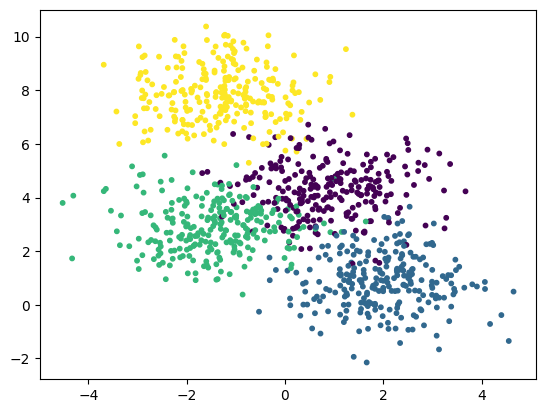

In [4]:
# Aanmaken van de dataset
X, y = make_blobs(n_samples=1000, centers=4, center_box=(-10, 10), random_state=0, cluster_std=1)
plt.scatter(X[:, 0], X[:, 1], s=10, c=y)
plt.show()

In [1]:
# splitsen in test set en training set


# ---------------------------------------------------
# normaliseren van de input data




In [10]:
# Test verschillende waarden voor de NN parameters: batch size, aantal epochs, dropoutrate


In [3]:
# Bouw een Sequentieel model met input layer, hidden layers en output layer

# Train het model



In [4]:
# Plot de trainingshistoriek (accuracy en loss) ifv het aantal epochs training


In [5]:
# Plot de decision boundaries van het model.  
# Maak hiertoe een rooster met een np.meshgrid, en voorspel de uitkomst voor elk punt in je gemaakte raster.
# Plot vervolgens de beslissingsgrens.



In [8]:
# Test de performantie met de test set en plot de confusion matrix en de accuracy score


In [ ]:
# Test verschillende Initializers

# Probeer verschillende optimizers uit: SGD, Adam, RMSProp, Adagrad, ... 
# (https://keras.io/optimizers/). Kijk wat er gebeurt in termen van de model loss curve en de accuracy.

# Test verschillende waardes voor de learning rate. Varieer bij SGD de learning rate en onderzoek wat er 
# gebeurt wanneer deze te klein of te groot wordt. 

# Kies een dropoutrate van 0.8. Verklaar wat er gebeurt. Zet nadien de dropout rate terug naar 0.0

# Verhoog het aantal neuronen in de hidden layers. Wat merk je? 

# Verhoog het aantal hidden layers.  Wat merk je? Bekijk de decision boundary. 
# Controleer of je met overfitting te maken hebt. Verhoog nu de dropout rate. Verklaar wat er gebeurt.

# Bespreek de invloed van batchnormalization.

# Probeer verschillende activatiefuncties uit bij de hidden layers. (https://keras.io/activations/)

# Doe hyperparameter tuning via grid search, random search en bayes optimization. 
# Wat is de finale accuracy die je haalt op de test set?

## Zalando 

Fashion-MNIST is een dataset van Zalando bestaande uit afbeeldingen van kledij. De training set ('fashion-mnist_train.csv') bestaat uit 60000 afbeeldingen, de test set ('fashion-mnist_test.csv') uit 10000 afbeeldingen.
Elke grijsafbeelding is 28x28 pixels groot en is toegewezen aan één van de 10 klasses: 

0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'.

Train een neuraal netwerk dat een zo hoog mogelijke accuracy score behaalt op de test set.
Eén optie is om als features de ruwe pixeldata (784 pixels) te gebruiken. Een andere benadering is om via Principle Component Analysis (PCA) de featureset te reduceren en daarmee als het ware feature extraction toe te passen.
Onderzoek welke afbeeldingen niet correct werden geclassificeerd en visualiseer ze.

Tijdens de volgende sessie zullen we op dezelfde dataset convolutional neural networks toepassen. Deze neurale netwerk architectuur leent zich uitstekend voor image classification.

Vergelijk jouw eigen accuracy score met deze opgelijst op https://github.com/zalandoresearch/fashion-mnist.


In [ ]:
df_train = pd.read_csv('../DATA/fashion-mnist_train.csv')
df_test = pd.read_csv('../DATA/fashion-mnist_test.csv')
df_train.head()

In [ ]:
# Uitwerking Zalando oefening
df_train.shape

In [ ]:
#Opsplitsen in features en targets
# values uit kolom label halen
train_labels = df_train.label.values
test_labels = df_test.label.values

y_test_orig = test_labels

y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

X_train = df_train.drop('label',axis=1).values
X_test  = df_test.drop('label',axis=1).values

print(y_train.shape)
print(y_test.shape)
print(X_train.shape)
print(X_test.shape)

# Uitwerking zonder Principal Components Analysis

In [ ]:
# scalen van de data


In [ ]:
# initialiseren van het neuraal netwerk


In [ ]:
# trainen

In [ ]:
# Plot history

# Accuray 


In [ ]:
# Inladen van het beste model


# Uitwerking met Principal Components Analysis

In [ ]:
# Principle Component Analysis

# Train het PCA algoritme op de training data


# Reduceer het aantal dimensies van zowel de trainig set als de test set

# Normaliseer de PCA componenten


In [ ]:
# initialiseren van het neuraal netwerk


# Model checkpoint


# Early stopping,...


In [ ]:
# Training


In [ ]:
# Plot history

# Accuray 

# Loss 


In [ ]:
# Inladen van het beste model

# Evalueren van het beste model


In [ ]:
# Aantal verkeerd geklassificeerde kledingstukken:


In [ ]:
# Visualisatie verkeerd geklasseerde kledingstukken

# aantal te tonen stukken 
